# Практическая работа № 7. Случайный лес

## Вариант B

**Цель:** обучить случайный лес, сравнить его с одиночным деревом решений, настроить основные гиперпараметры и содержательно проанализировать важность признаков.

В работе используется классификационный датасет **Telco Customer Churn** из предыдущей практики. Целевая переменная `Churn` показывает, ушёл ли клиент оператора связи.

План работы:

1. подготовить данные и сформировать единое train/test-разбиение;
2. сравнить одиночное дерево и случайный лес из 100 деревьев;
3. подобрать `n_estimators`, `max_depth`, `min_samples_leaf` кросс-валидацией;
4. исследовать встроенную важность признаков;
5. проверить качество после удаления наименее важных признаков.

Все случайные операции зафиксированы через `random_state=42`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 30)

## 1. Загрузка и первичный анализ данных

`customerID` — технический идентификатор, поэтому он исключается: запоминание идентификаторов не помогает обобщать модель на новых клиентов. Поле `TotalCharges` преобразуется в числовой формат; пустые строки после преобразования будут заполнены медианой, вычисленной только на обучающей выборке.

In [2]:
data_candidates = [
    Path("../data/Telco-Customer-Churn.csv"),          # запуск из practice7/notebooks
    Path("practice7/data/Telco-Customer-Churn.csv"),  # запуск из корня проекта
    Path("data/Telco-Customer-Churn.csv"),             # запуск из practice7
]
data_path = next((path for path in data_candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError("Не найден Telco-Customer-Churn.csv")

df = pd.read_csv(data_path)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print(f"Файл: {data_path.resolve()}")
print(f"Размер датасета: {df.shape[0]} строк × {df.shape[1]} столбцов")
print(f"Пропуски в TotalCharges после преобразования: {df['TotalCharges'].isna().sum()}")

class_distribution = (
    df["Churn"]
    .value_counts()
    .rename_axis("Churn")
    .to_frame("Количество")
    .assign(Доля=lambda table: table["Количество"] / len(df))
)
display(class_distribution.style.format({"Доля": "{:.1%}"}))
display(df.head())

Файл: /Users/nik/ml-hw/practice7/data/Telco-Customer-Churn.csv
Размер датасета: 7043 строк × 21 столбцов
Пропуски в TotalCharges после преобразования: 11


,Количество,Доля
Churn,,
No,5174,73.5%
Yes,1869,26.5%


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Единое разбиение и предобработка

Все модели обучаются и проверяются на **одном и том же** стратифицированном разбиении 75/25. Это делает сравнение корректным.

- числовые пропуски заполняются медианой;
- категориальные пропуски — наиболее частым значением;
- категориальные признаки кодируются методом One-Hot Encoding;
- предобработка находится внутри `Pipeline`, поэтому её параметры оцениваются только по train-части каждого фолда и утечки данных нет.

Масштабирование не применяется: деревья решений не зависят от масштаба признаков.

In [3]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y,
)


def make_preprocessor(feature_names):
    feature_names = list(feature_names)
    numeric_features = (
        X_train[feature_names].select_dtypes(exclude="object").columns.tolist()
    )
    categorical_features = (
        X_train[feature_names].select_dtypes(include="object").columns.tolist()
    )

    numeric_transformer = SimpleImputer(strategy="median")
    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "onehot",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            ),
        ]
    )

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_transformer, numeric_features),
            ("categorical", categorical_transformer, categorical_features),
        ]
    )


def make_pipeline(model, feature_names=None):
    if feature_names is None:
        feature_names = X_train.columns
    return Pipeline(
        steps=[
            ("preprocess", make_preprocessor(feature_names)),
            ("model", model),
        ]
    )


print(f"Train: {X_train.shape}; test: {X_test.shape}")
print(f"Доля Churn=Yes в train: {y_train.mean():.3f}")
print(f"Доля Churn=Yes в test:  {y_test.mean():.3f}")

Train: (5282, 19); test: (1761, 19)
Доля Churn=Yes в train: 0.265
Доля Churn=Yes в test:  0.265


## 3. Одиночное дерево и случайный лес

Сначала обучаются базовые модели без подбора гиперпараметров:

- `DecisionTreeClassifier` — одно дерево;
- `RandomForestClassifier(n_estimators=100)` — ансамбль из 100 деревьев.

Сто деревьев — разумная стартовая величина: она обычно уже заметно стабилизирует усреднённый прогноз, но не делает обучение слишком дорогим. Ниже это значение также сравнивается с 200 деревьями при кросс-валидации.

Из-за дисбаланса классов основной метрикой выбрана **ROC-AUC**. Дополнительно рассчитываются accuracy и F1 для положительного класса. Для леса выводится OOB accuracy: каждое дерево проверяется на объектах, не попавших в его bootstrap-выборку.

In [4]:
def evaluate_model(name, fitted_pipeline, X_eval=X_test, y_eval=y_test):
    prediction = fitted_pipeline.predict(X_eval)
    probability = fitted_pipeline.predict_proba(X_eval)[:, 1]
    estimator = fitted_pipeline.named_steps["model"]

    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_eval, prediction),
        "F1": f1_score(y_eval, prediction),
        "ROC-AUC": roc_auc_score(y_eval, probability),
        "OOB accuracy": getattr(estimator, "oob_score_", np.nan),
    }


decision_tree = make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))
default_forest = make_pipeline(
    RandomForestClassifier(
        n_estimators=100,
        oob_score=True,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
)

decision_tree.fit(X_train, y_train)
default_forest.fit(X_train, y_train)

baseline_results = pd.DataFrame(
    [
        evaluate_model("Decision Tree", decision_tree),
        evaluate_model("Random Forest, 100 деревьев", default_forest),
    ]
).set_index("Модель")

display(baseline_results.style.format("{:.3f}").highlight_max(axis=0, color="#d9ead3"))

,Accuracy,F1,ROC-AUC,OOB accuracy
Модель,,,,
Decision Tree,0.744,0.512,0.668,nan
"Random Forest, 100 деревьев",0.781,0.534,0.822,0.783


Случайный лес усредняет прогнозы деревьев, обученных на разных bootstrap-выборках и подмножествах признаков. Поэтому его разброс ниже, чем у одного глубокого дерева: обычно это повышает качество на новых данных, хотя отдельные деревья могут иметь меньшее смещение на train.

## 4. Настройка гиперпараметров с кросс-валидацией

Перебираются три требуемых гиперпараметра:

- `n_estimators`: 100 или 200 деревьев;
- `max_depth`: 8, 14 или без ограничения;
- `min_samples_leaf`: 1, 3 или 7 объектов в листе.

Всего проверяется 18 комбинаций на пяти стратифицированных фолдах. Выбор производится по среднему ROC-AUC. Тестовая выборка в подборе не участвует.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

forest_for_search = make_pipeline(
    RandomForestClassifier(
        oob_score=True,
        random_state=RANDOM_STATE,
        n_jobs=1,
    )
)

parameter_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [8, 14, None],
    "model__min_samples_leaf": [1, 3, 7],
}

grid_search = GridSearchCV(
    estimator=forest_for_search,
    param_grid=parameter_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
grid_search.fit(X_train, y_train)

tuning_results = (
    pd.DataFrame(grid_search.cv_results_)[
        [
            "param_model__n_estimators",
            "param_model__max_depth",
            "param_model__min_samples_leaf",
            "mean_train_score",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

print("Лучшие параметры:", grid_search.best_params_)
print(f"Лучший средний CV ROC-AUC: {grid_search.best_score_:.3f}")
display(tuning_results.head(10).style.format({
    "mean_train_score": "{:.3f}",
    "mean_test_score": "{:.3f}",
    "std_test_score": "{:.3f}",
}))

Лучшие параметры: {'model__max_depth': 8, 'model__min_samples_leaf': 7, 'model__n_estimators': 100}
Лучший средний CV ROC-AUC: 0.846


,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,100,8,7,0.895,0.846,0.015,1
1,200,8,7,0.895,0.846,0.015,2
2,100,8,3,0.907,0.845,0.014,3
3,200,8,3,0.908,0.845,0.014,4
4,200,14,7,0.917,0.845,0.013,5
5,200,None,7,0.917,0.845,0.013,6
6,100,None,7,0.917,0.845,0.014,7
7,100,14,7,0.917,0.845,0.014,8
8,200,8,1,0.919,0.844,0.014,9
9,100,8,1,0.918,0.844,0.014,10


## 5. Сравнение итоговых моделей

Настроенный лес сравнивается с одиночным деревом и лесом с параметрами по умолчанию на той же отложенной тестовой выборке.

,Accuracy,F1,ROC-AUC,OOB accuracy
Модель,,,,
Decision Tree,0.744,0.512,0.668,nan
"Random Forest, default (100)",0.781,0.534,0.822,0.783
"Random Forest, tuned",0.801,0.565,0.847,0.803


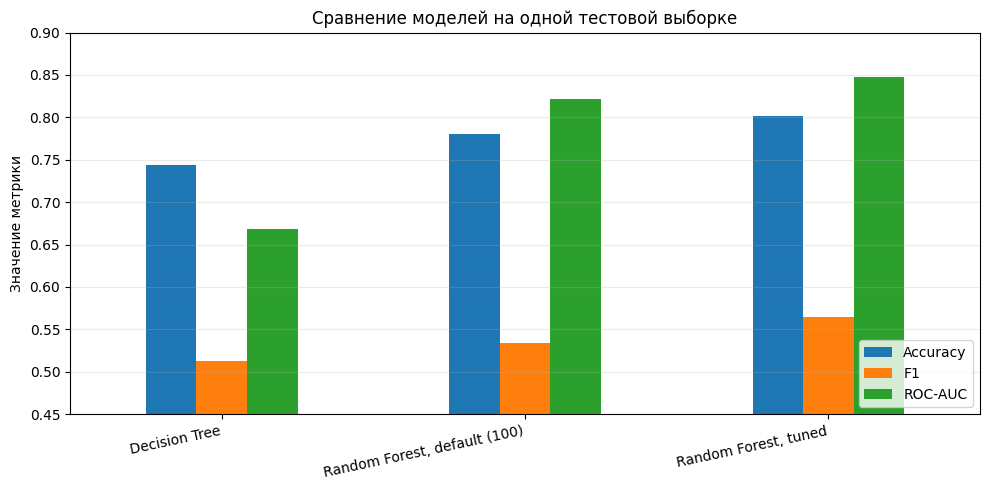

In [6]:
tuned_forest = grid_search.best_estimator_

comparison = pd.DataFrame(
    [
        evaluate_model("Decision Tree", decision_tree),
        evaluate_model("Random Forest, default (100)", default_forest),
        evaluate_model("Random Forest, tuned", tuned_forest),
    ]
).set_index("Модель")

display(comparison.style.format("{:.3f}").highlight_max(axis=0, color="#d9ead3"))

metric_columns = ["Accuracy", "F1", "ROC-AUC"]
comparison[metric_columns].plot(kind="bar", figsize=(10, 5), ylim=(0.45, 0.90))
plt.title("Сравнение моделей на одной тестовой выборке")
plt.ylabel("Значение метрики")
plt.xlabel("")
plt.xticks(rotation=12, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Встроенная важность признаков

`feature_importances_` показывает среднее уменьшение impurity, которое дали разбиения по признаку во всех деревьях. После One-Hot Encoding один исходный категориальный признак превращается в несколько столбцов, поэтому их важности суммируются обратно до уровня исходных признаков.

Полосы погрешности на графике — стандартное отклонение суммарной важности между деревьями ансамбля.

,importance,std
Contract,0.1753,0.1288
tenure,0.1523,0.1016
InternetService,0.1005,0.0766
TotalCharges,0.0984,0.0684
OnlineSecurity,0.0902,0.1007
PaymentMethod,0.0711,0.0753
TechSupport,0.0708,0.0859
MonthlyCharges,0.0540,0.0322
OnlineBackup,0.0329,0.0446
DeviceProtection,0.0287,0.0486


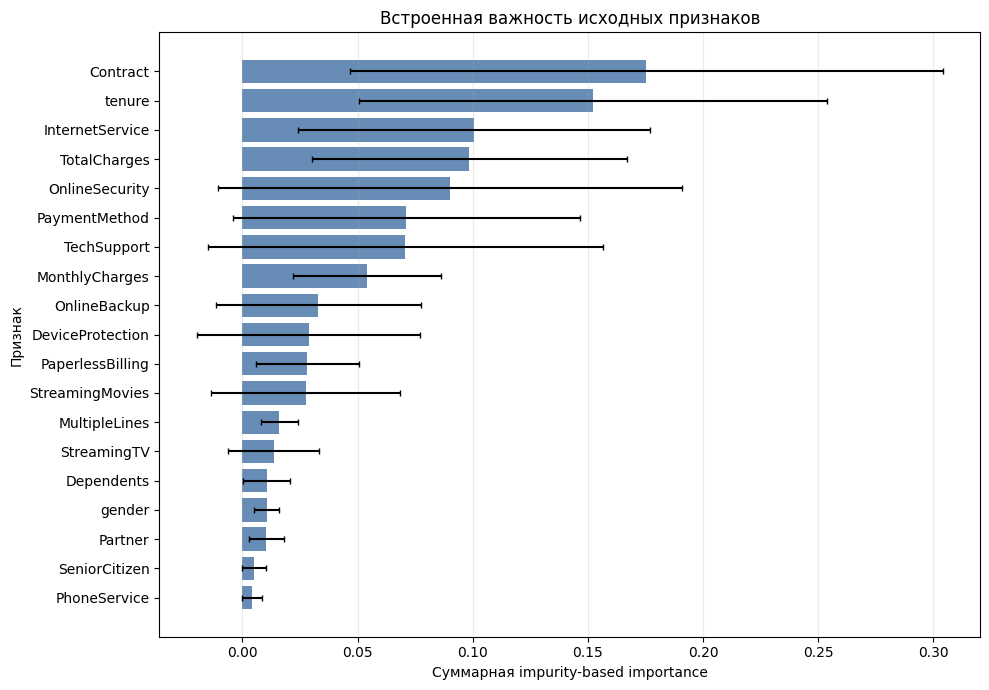

Два наиболее важных признака: Contract, tenure


In [7]:
fitted_preprocessor = tuned_forest.named_steps["preprocess"]
fitted_rf = tuned_forest.named_steps["model"]

numeric_features = list(fitted_preprocessor.transformers_[0][2])
categorical_features = list(fitted_preprocessor.transformers_[1][2])
onehot = fitted_preprocessor.named_transformers_["categorical"].named_steps["onehot"]

# Для каждого преобразованного столбца сохраняем имя исходного признака.
source_features = numeric_features.copy()
for feature, categories in zip(categorical_features, onehot.categories_):
    source_features.extend([feature] * len(categories))

transformed_feature_names = fitted_preprocessor.get_feature_names_out()
assert len(source_features) == len(transformed_feature_names)

# Используем feature_importances_ каждого дерева, затем агрегируем One-Hot столбцы.
per_tree_importances = np.vstack(
    [tree.feature_importances_ for tree in fitted_rf.estimators_]
)
per_tree_by_source = (
    pd.DataFrame(per_tree_importances.T, index=source_features)
    .groupby(level=0)
    .sum()
    .T
)

importance = pd.DataFrame(
    {
        "importance": per_tree_by_source.mean(axis=0),
        "std": per_tree_by_source.std(axis=0, ddof=0),
    }
).sort_values("importance", ascending=False)

display(importance.style.format("{:.4f}").bar(subset=["importance"], color="#6fa8dc"))

plot_data = importance.sort_values("importance")
plt.figure(figsize=(10, 7))
plt.barh(
    plot_data.index,
    plot_data["importance"],
    xerr=plot_data["std"],
    color="#4c78a8",
    alpha=0.85,
    capsize=2,
)
plt.title("Встроенная важность исходных признаков")
plt.xlabel("Суммарная impurity-based importance")
plt.ylabel("Признак")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

top_two_features = importance.head(2).index.tolist()
print("Два наиболее важных признака:", ", ".join(top_two_features))

### Содержательная интерпретация

Два наиболее важных признака — **`Contract`** и **`tenure`**.

- `Contract` отражает тип договора. Помесячный договор не удерживает клиента долгосрочными обязательствами, поэтому тип контракта хорошо разделяет группы риска.
- `tenure` показывает продолжительность отношений с компанией. Новые клиенты и давние клиенты имеют разные профили оттока.

Это **не причинно-следственные выводы**: важность говорит только о полезности признаков для разбиений конкретной модели. Коррелирующие признаки (`tenure`, `TotalCharges`, `MonthlyCharges`) могут делить важность между собой. Кроме того, impurity-based importance способна завышать значимость признаков с большим числом уникальных значений или возможных разбиений.

## 7. Эксперимент с удалением слабых признаков

Признаки сортируются по важности, вычисленной **только на train**. Затем последовательно удаляются наименее важные признаки, а модель с найденными гиперпараметрами заново обучается на том же train и проверяется на том же test.

Небольшие колебания неизбежны, поэтому практическим отсутствием потери считаем снижение ROC-AUC менее чем на 0,005. Для окончательной рекомендации дополнительно используем консервативный вариант — удаление только четырёх самых слабых признаков.

,Удалено,Осталось,Accuracy,F1,ROC-AUC,Удалённые признаки,Изменение ROC-AUC
0,0,19,0.801,0.565,0.847,—,+0.000
1,2,17,0.802,0.572,0.844,"PhoneService, SeniorCitizen",-0.003
2,4,15,0.804,0.569,0.845,"PhoneService, SeniorCitizen, Partner, gender",-0.002
3,6,13,0.804,0.574,0.844,"PhoneService, SeniorCitizen, Partner, gender, Dependents, StreamingTV",-0.003
4,8,11,0.804,0.581,0.843,"PhoneService, SeniorCitizen, Partner, gender, Dependents, StreamingTV, MultipleLines, StreamingMovies",-0.005
5,10,9,0.797,0.566,0.844,"PhoneService, SeniorCitizen, Partner, gender, Dependents, StreamingTV, MultipleLines, StreamingMovies, PaperlessBilling, DeviceProtection",-0.003
6,12,7,0.802,0.586,0.843,"PhoneService, SeniorCitizen, Partner, gender, Dependents, StreamingTV, MultipleLines, StreamingMovies, PaperlessBilling, DeviceProtection, OnlineBackup, MonthlyCharges",-0.005
7,13,6,0.800,0.589,0.842,"PhoneService, SeniorCitizen, Partner, gender, Dependents, StreamingTV, MultipleLines, StreamingMovies, PaperlessBilling, DeviceProtection, OnlineBackup, MonthlyCharges, TechSupport",-0.005
8,14,5,0.791,0.542,0.837,"PhoneService, SeniorCitizen, Partner, gender, Dependents, StreamingTV, MultipleLines, StreamingMovies, PaperlessBilling, DeviceProtection, OnlineBackup, MonthlyCharges, TechSupport, PaymentMethod",-0.010


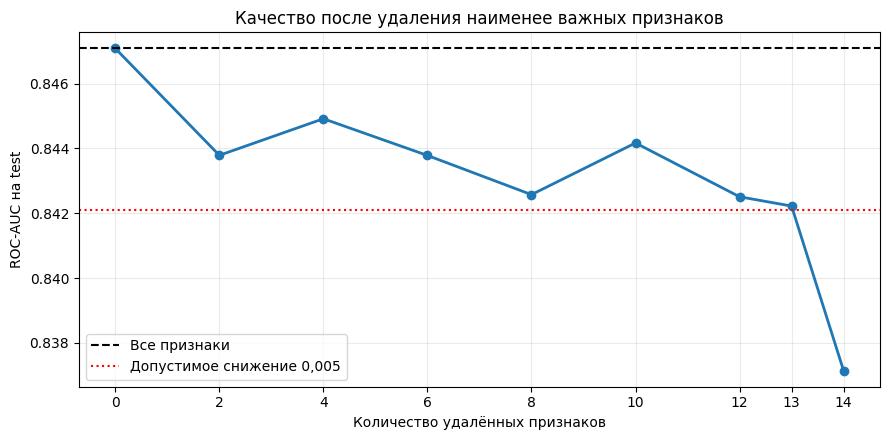

Консервативные кандидаты на исключение: PhoneService, SeniorCitizen, Partner, gender
ROC-AUC после их удаления: 0.845
Изменение относительно полной модели: -0.002


In [8]:
best_rf_parameters = {
    key.removeprefix("model__"): value
    for key, value in grid_search.best_params_.items()
}
least_important_first = importance.sort_values("importance").index.tolist()

removal_counts = [0, 2, 4, 6, 8, 10, 12, 13, 14]
removal_experiment = []

for count in removal_counts:
    removed = least_important_first[:count]
    kept = [feature for feature in X_train.columns if feature not in removed]

    reduced_forest = make_pipeline(
        RandomForestClassifier(
            **best_rf_parameters,
            oob_score=True,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        feature_names=kept,
    )
    reduced_forest.fit(X_train[kept], y_train)

    prediction = reduced_forest.predict(X_test[kept])
    probability = reduced_forest.predict_proba(X_test[kept])[:, 1]
    removal_experiment.append(
        {
            "Удалено": count,
            "Осталось": len(kept),
            "Accuracy": accuracy_score(y_test, prediction),
            "F1": f1_score(y_test, prediction),
            "ROC-AUC": roc_auc_score(y_test, probability),
            "Удалённые признаки": ", ".join(removed) if removed else "—",
        }
    )

removal_results = pd.DataFrame(removal_experiment)
baseline_auc = removal_results.loc[removal_results["Удалено"] == 0, "ROC-AUC"].iloc[0]
removal_results["Изменение ROC-AUC"] = removal_results["ROC-AUC"] - baseline_auc

display(removal_results.style.format({
    "Accuracy": "{:.3f}",
    "F1": "{:.3f}",
    "ROC-AUC": "{:.3f}",
    "Изменение ROC-AUC": "{:+.3f}",
}))

plt.figure(figsize=(9, 4.5))
plt.plot(
    removal_results["Удалено"],
    removal_results["ROC-AUC"],
    marker="o",
    linewidth=2,
)
plt.axhline(baseline_auc, color="black", linestyle="--", label="Все признаки")
plt.axhline(
    baseline_auc - 0.005,
    color="red",
    linestyle=":",
    label="Допустимое снижение 0,005",
)
plt.title("Качество после удаления наименее важных признаков")
plt.xlabel("Количество удалённых признаков")
plt.ylabel("ROC-AUC на test")
plt.xticks(removal_counts)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

conservative_removed = least_important_first[:4]
row_four = removal_results.loc[removal_results["Удалено"] == 4].iloc[0]
print("Консервативные кандидаты на исключение:", ", ".join(conservative_removed))
print(f"ROC-AUC после их удаления: {row_four['ROC-AUC']:.3f}")
print(f"Изменение относительно полной модели: {row_four['Изменение ROC-AUC']:+.3f}")

## 8. Выводы

1. На одном и том же разбиении одиночное дерево заметно уступило случайному лесу. Бэггинг уменьшил разброс модели и повысил качество на test.
2. Кросс-валидация выбрала лес из **100 деревьев** с `max_depth=8` и `min_samples_leaf=7`. Увеличение ансамбля до 200 деревьев не улучшило средний CV ROC-AUC настолько, чтобы оправдать дополнительное время обучения, поэтому 100 деревьев достаточно.
3. Настроенный лес улучшил тестовый ROC-AUC по сравнению и с одиночным деревом, и с лесом на параметрах по умолчанию. OOB accuracy близка к тестовой accuracy, что служит дополнительной внутренней проверкой обобщающей способности ансамбля.
4. Наиболее важными оказались **`Contract`** и **`tenure`**. Их важность описывает статистическую полезность для модели, но не доказывает причинность.
5. Консервативно можно исключить **`PhoneService`**, **`SeniorCitizen`**, **`Partner`** и **`gender`**: в проведённом эксперименте удаление этих четырёх признаков не вызвало практического снижения ROC-AUC. Более агрессивное удаление также иногда даёт близкую метрику из-за корреляций и случайности ансамбля, однако такую сокращённую модель следует дополнительно проверить на повторных разбиениях или внешней выборке.